# Notebook 03 — Joining & Exploration

**Goal:** build one fact table (validations → routes → vehicles → stops), prove that the joins did not create or lose rows, add a trip-level load factor, and explore the data visually.

**Input:** `data/interim/*_clean.parquet` **Output:** `data/interim/fact_validations.parquet`

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid", palette="deep")

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"

validations = pd.read_parquet(INTERIM_DIR / "validations_clean.parquet")
routes = pd.read_parquet(INTERIM_DIR / "routes_clean.parquet")
vehicles = pd.read_parquet(INTERIM_DIR / "vehicles_clean.parquet")
stops = pd.read_parquet(INTERIM_DIR / "stops_clean.parquet")

for name, df in {"validations": validations, "routes": routes, "vehicles": vehicles, "stops": stops}.items():
    print(f"{name:<12} {df.shape}")

validations  (79149, 21)
routes       (60, 6)
vehicles     (180, 6)
stops        (400, 5)


## 1. Join strategy

| Join | Type | Why |
|---|---|---|
| validations → routes | `left`, `many_to_one` | Every clean validation must stay in the fact table. Notebook 02 already removed unknown route IDs, so an `inner` join would give the same rows — but `left` makes any future mismatch visible as nulls (checked below) instead of silently deleting boardings. |
| → vehicles | `left`, `many_to_one` | Same reasoning; adds capacity, type, depot and age band. |
| → stops | `left`, `many_to_one` | Same reasoning; adds the stop's district, zone and shelter. |

`validate="many_to_one"` makes pandas raise an error if a master table ever contains the same key twice, which is exactly the situation that causes a silent fan-out (more rows after the join than before).

Routes and stops both have a `district` column. They mean different things — the district a route is assigned to vs. the district where the passenger boarded — so they are renamed to `route_district` and `stop_district` before joining, instead of ending up as the unclear `district_x` / `district_y`.

In [2]:
routes_j = routes.rename(columns={"district": "route_district"})
stops_j = stops.rename(columns={"district": "stop_district"})

n_validations = len(validations)

fact = (
    validations
    .merge(routes_j, on="route_id", how="left", validate="many_to_one")
    .merge(vehicles, on="vehicle_id", how="left", validate="many_to_one")
    .merge(stops_j, on="stop_id", how="left", validate="many_to_one")
)

assert len(fact) == n_validations, (
    f"Join changed the row count: {n_validations:,} validations -> {len(fact):,} fact rows"
)

master_columns = ["route_name", "mode", "capacity", "vehicle_type", "stop_name", "zone"]
unmatched = fact[master_columns].isna().sum()
assert unmatched.sum() == 0, f"Unmatched keys after join:\n{unmatched}"

print(f"Row count check passed: {len(fact):,} rows, {fact.shape[1]} columns, no unmatched keys")

Row count check passed: 79,149 rows, 35 columns, no unmatched keys


The fact table has exactly as many rows as the clean validations and every validation found its route, vehicle and stop.

## 2. Trip-level load factor

Dividing one validation's passenger count by the vehicle's capacity (1 / 200 = 0.005) says nothing about how full the vehicle was. Load is only meaningful for a **trip**, so a trip is defined here as *one vehicle on one route on one date in one clock hour*:

`load_factor = boardings on that trip / vehicle capacity`

Net boardings are used (reversals subtract) and clipped at zero. Every validation row receives the load factor of its trip, together with a `trip_id`, so Notebook 04 can average load factors **per trip** rather than per validation row.

In [3]:
TRIP_KEYS = ["vehicle_id", "route_id", "date", "hour"]

trips = (
    fact.groupby(TRIP_KEYS, as_index=False)
    .agg(trip_boardings=("passenger_count", "sum"), capacity=("capacity", "first"))
)
trips["trip_boardings"] = trips["trip_boardings"].clip(lower=0)
trips["load_factor"] = (trips["trip_boardings"] / trips["capacity"]).round(4)
trips["trip_id"] = trips.index.astype("int64")

fact = fact.merge(
    trips[TRIP_KEYS + ["trip_id", "trip_boardings", "load_factor"]],
    on=TRIP_KEYS, how="left", validate="many_to_one",
)
assert len(fact) == n_validations and fact["load_factor"].notna().all()

print(f"Trips: {len(trips):,}  |  validations per trip: {n_validations / len(trips):.2f}")
trips["load_factor"].describe(percentiles=[0.5, 0.9, 0.99]).round(4)

Trips: 78,741  |  validations per trip: 1.01


count    78741.0000
mean         0.0097
std          0.0065
min          0.0000
50%          0.0085
90%          0.0161
99%          0.0385
max          0.0806
Name: load_factor, dtype: float64

The load factors are very low (median 0.0085): almost every trip records just one validation (1.01 on average). This is a property of the dataset (about 80,000 validations spread over 180 vehicles and 182 days), not a calculation error. In practice the load factor here mostly reflects vehicle size (1 / capacity), so it can be used to compare vehicle types but **not** to say how full a vehicle really was. This limitation is noted in the README.

## 3. Exploration

Boardings are always measured as `passenger_count` (net of reversals), not as the number of validation rows.

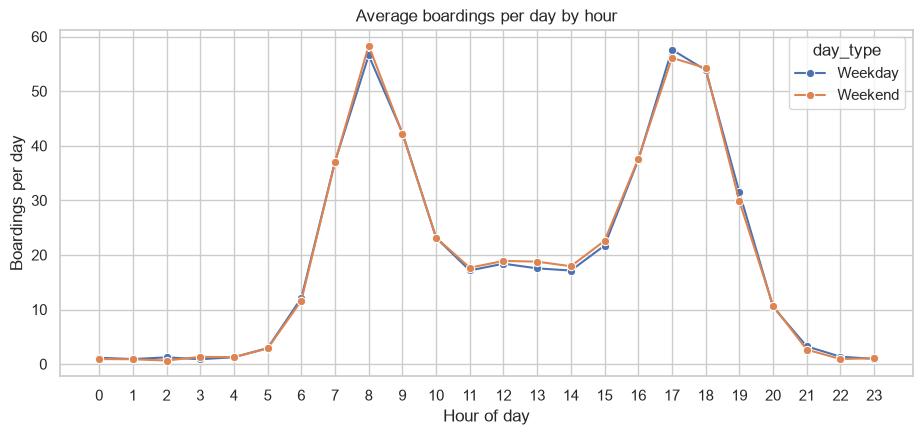

In [4]:
days = fact.groupby("is_weekend")["date"].nunique()
hourly = (
    fact.groupby(["is_weekend", "hour"])["passenger_count"].sum()
    .div(days, level="is_weekend")
    .rename("avg_boardings_per_day")
    .reset_index()
)
hourly["day_type"] = hourly["is_weekend"].map({False: "Weekday", True: "Weekend"})

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.lineplot(data=hourly, x="hour", y="avg_boardings_per_day", hue="day_type", marker="o", ax=ax)
ax.set(title="Average boardings per day by hour", xlabel="Hour of day", ylabel="Boardings per day",
       xticks=range(24))
plt.show()

Weekdays show the classic commuter double peak: about 57 boardings per day at 08:00 and again at 17:00, three times the midday level. The weekend curve lies almost exactly on top of the weekday curve, peaks included.

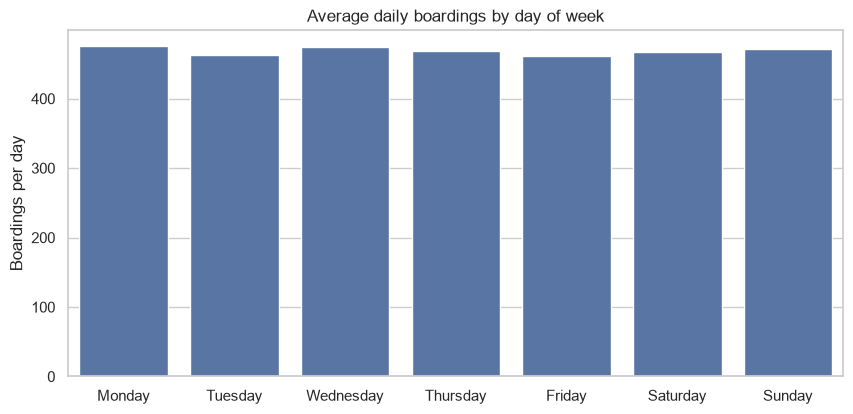

day_of_week
Monday       475.1
Tuesday      462.3
Wednesday    474.0
Thursday     468.0
Friday       460.7
Saturday     466.8
Sunday       471.7
Name: passenger_count, dtype: float64

In [5]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
per_day = fact.groupby(["date", "day_of_week"], as_index=False)["passenger_count"].sum()

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=per_day, x="day_of_week", y="passenger_count", order=day_order,
            estimator="mean", errorbar=None, ax=ax)
ax.set(title="Average daily boardings by day of week", xlabel="", ylabel="Boardings per day")
plt.show()
per_day.groupby("day_of_week")["passenger_count"].mean().reindex(day_order).round(1)

Average daily boardings are almost the same on every day of the week, including Saturday and Sunday.

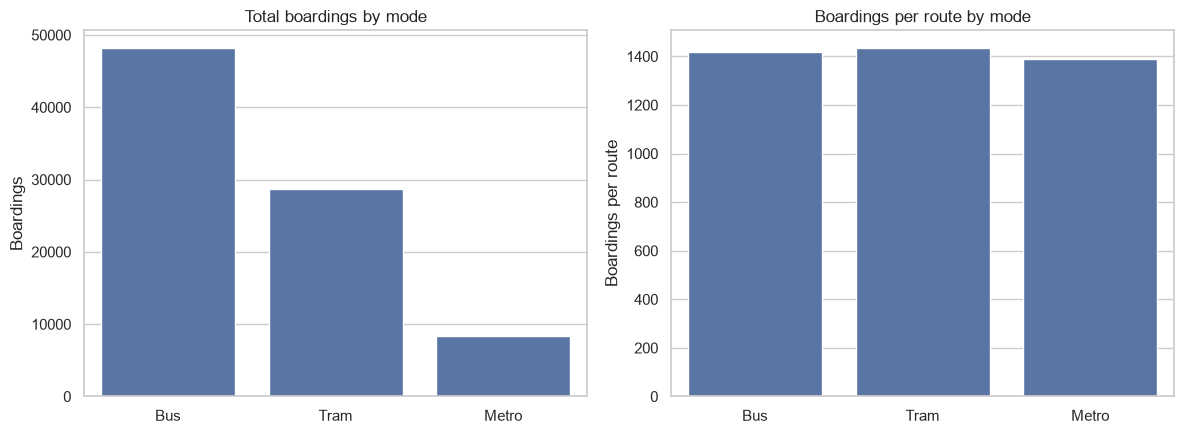

,boardings,routes,avg_trip_load,boardings_per_route
mode,,,,
Bus,48211,34,0.013601,1418.0
Tram,28706,20,0.005511,1435.0
Metro,8330,6,0.001854,1388.0


In [6]:
mode_summary = fact.groupby("mode").agg(
    boardings=("passenger_count", "sum"),
    routes=("route_id", "nunique"),
    avg_trip_load=("load_factor", "mean"),
)
mode_summary["boardings_per_route"] = (mode_summary["boardings"] / mode_summary["routes"]).round(0)
mode_summary = mode_summary.sort_values("boardings", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(x=mode_summary.index, y=mode_summary["boardings"], ax=axes[0])
axes[0].set(title="Total boardings by mode", xlabel="", ylabel="Boardings")
sns.barplot(x=mode_summary.index, y=mode_summary["boardings_per_route"], ax=axes[1])
axes[1].set(title="Boardings per route by mode", xlabel="", ylabel="Boardings per route")
plt.tight_layout()
plt.show()
mode_summary

Bus carries the most passengers in total because it has the most routes, but per route all three modes carry a similar number of passengers.

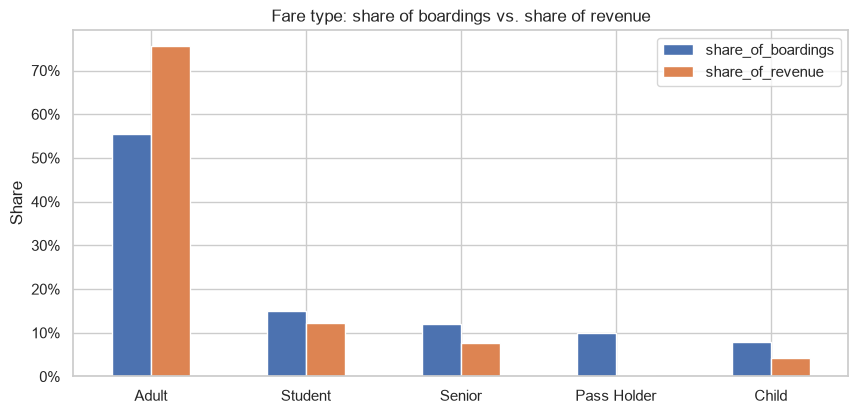

,boardings,revenue,share_of_boardings,share_of_revenue
fare_type,,,,
Adult,47278,118196.62,0.56,0.76
Student,12719,19045.83,0.15,0.12
Senior,10113,12106.66,0.12,0.08
Pass Holder,8468,488.05,0.10,0.00
Child,6669,6653.09,0.08,0.04


In [7]:
fare_mix = (
    fact.groupby("fare_type")
    .agg(boardings=("passenger_count", "sum"), revenue=("revenue", "sum"))
    .sort_values("boardings", ascending=False)
)
fare_mix["share_of_boardings"] = (fare_mix["boardings"] / fare_mix["boardings"].sum()).round(3)
fare_mix["share_of_revenue"] = (fare_mix["revenue"] / fare_mix["revenue"].sum()).round(3)

fig, ax = plt.subplots(figsize=(10, 4.5))
fare_mix[["share_of_boardings", "share_of_revenue"]].plot.bar(ax=ax, rot=0)
ax.set(title="Fare type: share of boardings vs. share of revenue", xlabel="", ylabel="Share")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.show()
fare_mix.round(2)

Adult tickets are just over half of the boardings but bring in about three quarters of the fare revenue. Pass holders are about 10% of boardings and pay almost nothing per ride, because their pass is paid separately.

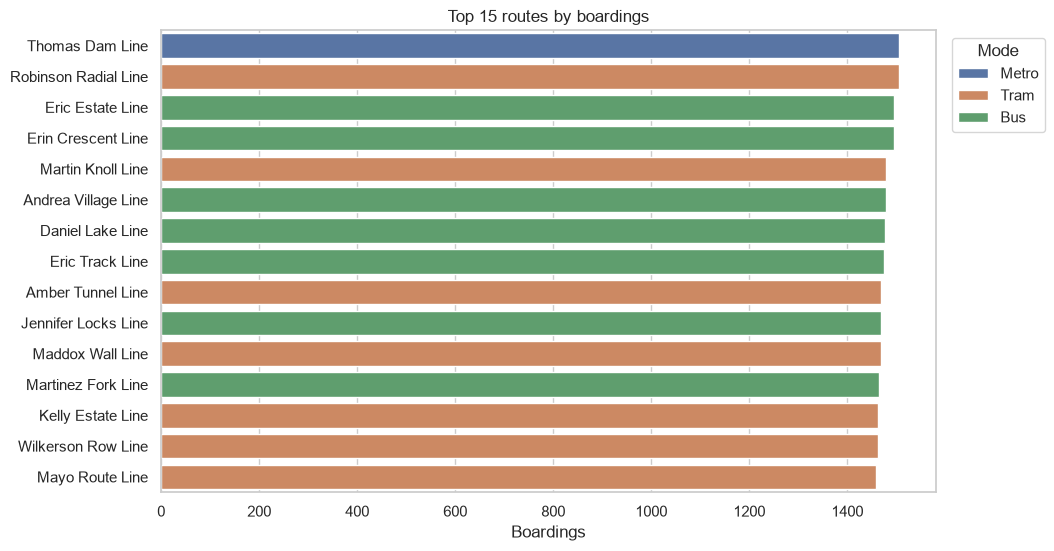

Top 10 of 60 routes carry 17.4% of boardings
Busiest route vs. quietest route: 1,506 vs. 1,340


In [8]:
top_routes = (
    fact.groupby(["route_name", "mode"], as_index=False)["passenger_count"].sum()
    .nlargest(15, "passenger_count")
)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=top_routes, y="route_name", x="passenger_count", hue="mode", dodge=False, ax=ax)
ax.set(title="Top 15 routes by boardings", xlabel="Boardings", ylabel="")
ax.legend(title="Mode", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.show()

route_totals = fact.groupby("route_id")["passenger_count"].sum().sort_values(ascending=False)
print(f"Top 10 of 60 routes carry {route_totals.head(10).sum() / route_totals.sum():.1%} of boardings")
print(f"Busiest route vs. quietest route: {route_totals.max():,} vs. {route_totals.min():,}")

Ridership is spread very evenly: the 10 busiest routes carry 17.4% of boardings, barely more than their "fair share" of 10/60 = 16.7%, and the busiest route has only about 12% more boardings than the quietest.

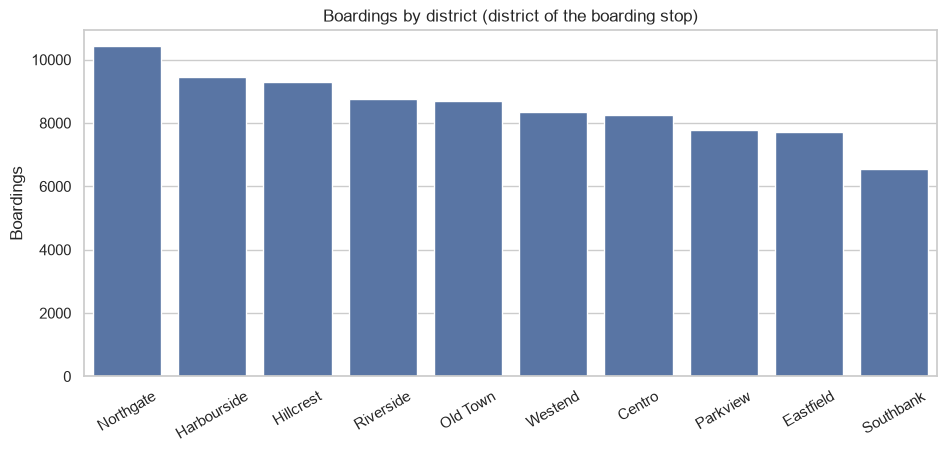

,boardings,stops,boardings_per_stop
stop_district,,,
Northgate,10419,48,217.0
Harbourside,9443,45,210.0
Hillcrest,9295,44,211.0
Riverside,8772,41,214.0
Old Town,8679,41,212.0
Westend,8355,40,209.0
Centro,8260,39,212.0
Parkview,7783,36,216.0
Eastfield,7705,36,214.0


In [9]:
district = (
    fact.groupby("stop_district")
    .agg(boardings=("passenger_count", "sum"), stops=("stop_id", "nunique"))
    .sort_values("boardings", ascending=False)
)
district["boardings_per_stop"] = (district["boardings"] / district["stops"]).round(0)

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(x=district.index, y=district["boardings"], ax=ax)
ax.set(title="Boardings by district (district of the boarding stop)", xlabel="", ylabel="Boardings")
plt.xticks(rotation=30)
plt.show()
district

Northgate has the most boardings, but it also has the most stops. Per stop, every district is between 209 and 218 boardings, so district totals mainly reflect how many stops a district has.

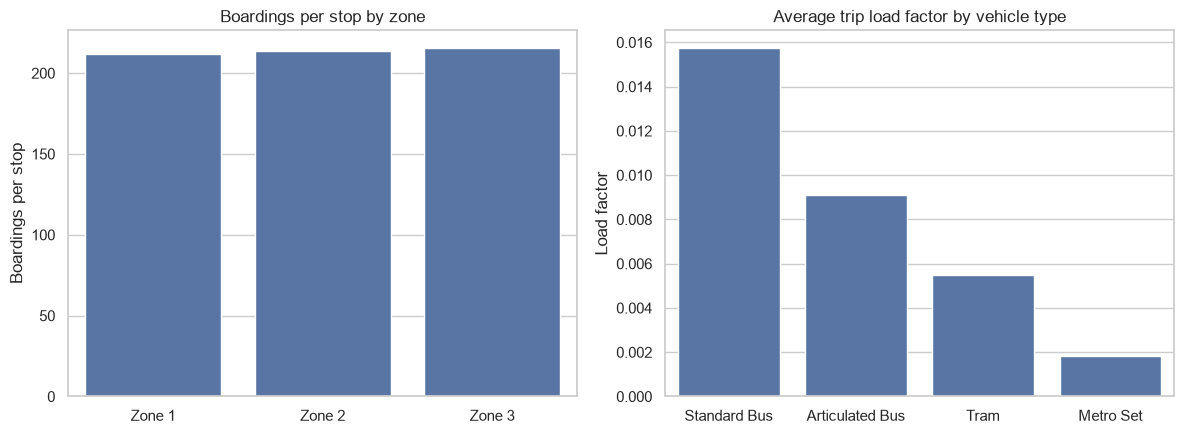

,boardings,stops,boardings_per_stop
zone,,,
Zone 1,45168,213,212.1
Zone 2,23049,108,213.4
Zone 3,17030,79,215.6


vehicle_type
Standard Bus       0.0158
Articulated Bus    0.0091
Tram               0.0055
Metro Set          0.0018
Name: load_factor, dtype: float64

In [10]:
zone = fact.groupby("zone").agg(boardings=("passenger_count", "sum"), stops=("stop_id", "nunique"))
zone["boardings_per_stop"] = (zone["boardings"] / zone["stops"]).round(1)

vehicle_load = (
    fact.drop_duplicates("trip_id")
    .groupby("vehicle_type")["load_factor"].mean()
    .sort_values(ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(x=zone.index, y=zone["boardings_per_stop"], ax=axes[0])
axes[0].set(title="Boardings per stop by zone", xlabel="", ylabel="Boardings per stop")
sns.barplot(x=vehicle_load.index, y=vehicle_load.values, ax=axes[1])
axes[1].set(title="Average trip load factor by vehicle type", xlabel="", ylabel="Load factor")
plt.tight_layout()
plt.show()
display(zone)
vehicle_load.round(4)

Boardings per stop are almost identical in the three zones. Boardings per stop are almost identical in the three zones (212–216). Average load factor is highest on standard buses and lowest on metro sets, because metro sets have about nine times the capacity of a standard bus while each trip records a similar number of validations.

## 4. Three things I did not expect

1. **Weekends are as busy as weekdays.** Every day of the week averages 460–475 boardings, and the weekend hourly curve has the same 08:00 and 17:00 peaks as weekdays. A real city network normally loses a large part of its commuters on Saturday and Sunday, so either this network serves a very unusual population or the weekend timetable already needs peak-level capacity. It is worth checking with the agency before reducing weekend service.

2. **No route, stop or district stands out.** The busiest route has only 12% more boardings than the quietest (1,506 vs. 1,340), and boardings per stop are about 210 in every district and zone. The brief asks "which routes are overloaded", but on this data the honest answer is that demand is evenly spread. Route totals differ mainly because routes, stops and districts differ in size, not in popularity.

3. **Metro carries the same per route as bus, with nine times the capacity.** Bus, tram and metro each carry about 1,400 boardings per route over six months. A metro set holds about 620 people against about 70 on a standard bus, so per seat the metro is by far the least used mode. Its trip load factor (0.002) is about one seventh of the bus figure (0.014). If the validation data is complete, the metro is the clearest candidate for capacity review (shorter trains or lower off-peak frequency).

## 5. Save the fact table

In [11]:
out = INTERIM_DIR / "fact_validations.parquet"
fact.to_parquet(out, index=False)
print(f"Saved {out.relative_to(PROJECT_ROOT)}: {fact.shape[0]:,} rows x {fact.shape[1]} columns")

Saved data\interim\fact_validations.parquet: 79,149 rows x 38 columns


**Next:** `04_aggregate_and_export.ipynb` builds the nine aggregate tables for Power BI.